<a href="https://colab.research.google.com/github/AP24110010586-U/ML/blob/main/Hierarchical_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Hierarchical Clustering in Machine Learning**


In [11]:
import pandas as pd
import numpy as np

# Create a synthetic toy dataset                                                                             #AP24110010586
np.random.seed(42)
data_dict = {
    'Illness': np.random.choice(['Yes', 'No'], size=150),
    'City': np.random.choice(['New York', 'Los Angeles', 'Chicago'], size=150),
    'Gender': np.random.choice(['Male', 'Female'], size=150),
    'Age': np.random.randint(18, 65, size=150),
    'Income': np.random.randint(20000, 120000, size=150),
    'House_Value': np.random.randint(100000, 500000, size=150)
}

df = pd.DataFrame(data_dict)
df.to_csv('toy_dataset.csv', index=False)
print("Synthesized 'toy_dataset.csv' has been successfully created in the current directory!")
display(df.head())

Synthesized 'toy_dataset.csv' has been successfully created in the current directory!


,Illness,City,Gender,Age,Income,House_Value
0,Yes,Chicago,Male,38,92369,218874
1,No,Chicago,Female,49,31938,387433
2,Yes,New York,Female,40,55195,324786
3,Yes,Chicago,Male,50,111680,115485
4,Yes,New York,Female,20,24000,406626


Hierarchical clustering is an unsupervised machine learning technique used to group similar data points into clusters. It works by finding similarities between data points and grouping them step by step. It helps in identifying patterns and relationships in data.

In [12]:
import pandas as pd

try:
    # Load the toy dataset
    data = pd.read_csv('toy_dataset.csv')
    print("Dataset successfully loaded!")

    # Preprocess: drop categorical columns so that it contains only numeric data for clustering
    data.drop(columns=['Illness', 'City', 'Gender'], inplace=True, errors='ignore')
    print("Categorical columns dropped. Ready for clustering!")
    display(data.head())
except FileNotFoundError:
    print("The file 'toy_dataset.csv' was not found. Please run cell 5b2afe3b first.")

Dataset successfully loaded!
Categorical columns dropped. Ready for clustering!


,Age,Income,House_Value
0,38,92369,218874
1,49,31938,387433
2,40,55195,324786
3,50,111680,115485
4,20,24000,406626


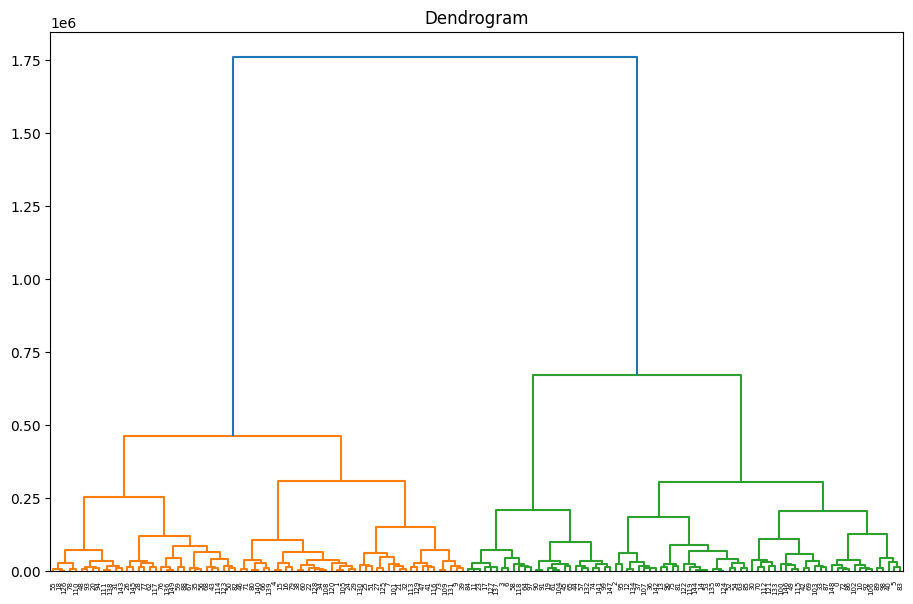

In [13]:
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc

plt.figure(figsize=(11,7))
plt.title("Dendrogram")

dendrogram = shc.dendrogram(shc.linkage(data, method='ward'))

This code performs hierarchical clustering and creates a dendrogram to show how similar data points are grouped together. The Ward method is used to form clusters by minimizing the variation within them. The graph helps in understanding how the clusters are formed.

#**Types of Hierarchal Clustering**

There are two types of hierarchal clustering:

1.Agglomerative clustering

2.Divisive Clustering

**1.Agglomerative Clustering**

In [15]:
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
                                                                                                            #AP24110010586
# 'affinity' has been renamed to 'metric' in newer versions of scikit-learn
cluster = AgglomerativeClustering(n_clusters=5, metric='l1', linkage='single')
data = pd.read_csv('toy_dataset.csv')
data.drop(columns=['Illness', 'City', 'Gender'], inplace=True, errors='ignore')
cluster.fit_predict(data)

array([0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 1, 4, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 4, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 2, 0, 0, 0, 1, 1, 0, 0, 0, 2, 0, 3, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 4, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1])

Agglomerative clustering starts by treating each data point as a separate cluster. Similar clusters are gradually merged based on the distance between them. This process continues until all data points are grouped into clusters.

**2.Divisive Clustering**

**Importing Required Libraries**

In [19]:
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# Defining the DistanceMatrix function using scipy to replace the missing import
def DistanceMatrix(data):
    # Calculates the pairwise Euclidean distance matrix
    return cdist(data, data, metric='euclidean')

Divisive clustering starts with all data points in a single cluster and gradually divides them into smaller clusters based on similarities and distances. This process continues until the required clusters are formed.

**Creating The Diana Class**

In [22]:
class DianakClustering:
    def __init__(self, datak):
        self.data = datak
        self.n_samples, self.n_features = datak.shape

    def fit(self, no_clusters):
        similarity_matrix = DistanceMatrix(self.data.values if isinstance(self.data, pd.DataFrame) else self.data)
        # Start with all samples in a single cluster
        clusters = [list(range(self.n_samples))]

        while len(clusters) < no_clusters:
            # Find the cluster with the maximum diameter (maximum distance between any two elements)
            diameters = []
            for c in clusters:
                if len(c) <= 1:
                    diameters.append(0)
                else:
                    # Extract submatrix of similarities for the cluster elements
                    sub_matrix = similarity_matrix[np.ix_(c, c)]
                    diameters.append(np.max(sub_matrix))

            mcd = np.argmax(diameters)  # Index of cluster to split
            lc = list(clusters[mcd])    # Splitting cluster

            if len(lc) <= 1:
                break  # Cannot split further

            # Find the element with maximum average distance to all other elements in this cluster
            sub_matrix = similarity_matrix[np.ix_(lc, lc)]
            avg_dist = np.mean(sub_matrix, axis=1)
            max_diff_idx = np.argmax(avg_dist)

            # 'spin' will be the new splinter group
            spin = [lc[max_diff_idx]]                                                                 #AP24110010586
            del lc[max_diff_idx]

            # Iteratively move elements from 'lc' to 'spin' if they are closer to 'spin' than 'lc'
            while True:
                split = False
                for j in range(len(lc) - 1, -1, -1):
                    item = lc[j]
                    dist_to_spin = np.mean(similarity_matrix[item, spin])
                    remaining_lc = [x for x in lc if x != item]
                    if len(remaining_lc) > 0:
                        dist_to_lc = np.mean(similarity_matrix[item, remaining_lc])
                    else:
                        dist_to_lc = 0

                    if dist_to_spin <= dist_to_lc:
                        spin.append(item)
                        del lc[j]
                        split = True
                        break
                if not split:
                    break

            # Update the cluster list
            del clusters[mcd]
            clusters.append(spin)
            clusters.append(lc)

        # Prepare final cluster labels
        cluster_labels = np.zeros(self.n_samples, dtype=int)
        for i, c in enumerate(clusters):
            for element in c:
                cluster_labels[element] = i

        return cluster_labels

In [24]:
if __name__ == '__main__':
    # Use the synthesized dataset file available in our directory
    data = pd.read_csv('toy_dataset.csv')
    # Drop the categorical columns present in our toy dataset
    data = data.drop(columns=["Illness", "City", "Gender"], errors="ignore")

    # Instantiate the correct class name defined in cell Vp_8VHVyhOS_
    dianak = DianakClustering(data)
    clusters = dianak.fit(3)
    print("Cluster labels generated successfully:")
    print(clusters)

Cluster labels generated successfully:
[2 0 0 1 0 1 1 0 2 0 2 1 2 2 2 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 2 0 0 2 0 0 2
 2 0 0 1 0 2 0 1 1 0 0 0 2 0 2 2 2 2 0 0 1 1 0 0 1 0 2 1 1 0 0 0 2 2 0 2 0
 1 2 0 0 0 0 0 2 0 1 1 2 2 2 0 1 1 1 2 0 0 0 2 1 1 1 2 0 2 2 1 0 2 2 0 0 0
 0 2 0 0 2 0 0 1 2 0 2 2 0 2 0 0 1 0 0 2 0 1 2 2 2 0 1 0 0 0 1 2 0 2 0 1 1
 2 0]


**CONCLUSION**

Hierarchical clustering is a useful technique for grouping similar data points. It uses dendrograms to visualize clusters and has two types: agglomerative and divisive. It works well with small datasets but can be slow and costly for large datasets.